## **Learning Curve**
Kurva pembelajaran digunakan untuk melihat bagaimana performa model berubah ketika kita menambah jumlah sampel data pelatihan.

- Sumbu X: Ukuran data pelatihan / jumlah sampel (misal: 100 sampel, 400 sampel, 800 sampel, dst).
- Sumbu Y: Skor performa atau tingkat error (seperti grafik kualitas anggur yang kamu buat kedua).
- Hyperparameter Model: Tetap/konstan (tidak diubah-ubah selama proses).

### **Studi Kasus: Dataset Kualitas Anggur**
Tujuan: Analisis apakah menambah lebih banyak sampel meningkatkan prediksi kualitas anggur.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve

In [10]:
df = pd.read_csv(r'E:\DigitalentDA\Datasets\winequality-red.csv')

print(df.head())
print(df.info())
print(df.describe())

   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 

In [11]:
X = df.drop(columns=['quality'])
y = df['quality']

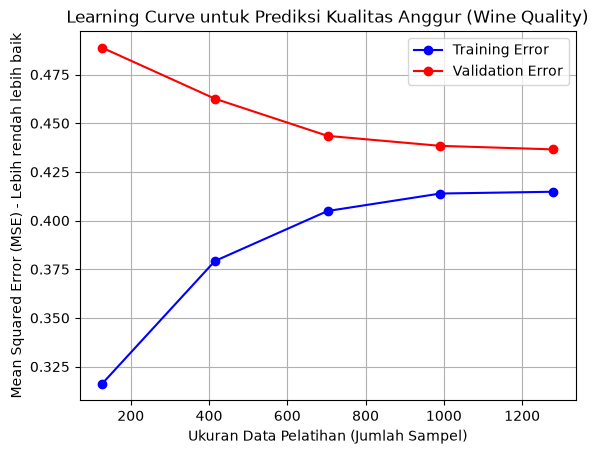

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    LinearRegression(),
    X,
    y,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 5),
    scoring="neg_mean_squared_error",
    random_state=42,
)

train_mean = -train_scores.mean(axis=1)
test_mean = -test_scores.mean(axis=1)

plt.plot(train_sizes, train_mean, "o-", color="blue", label='Training Error')
plt.plot(train_sizes, test_mean, "o-", color="red", label='Validation Error')

plt.xlabel("Ukuran Data Pelatihan (Jumlah Sampel)")
plt.ylabel("Mean Squared Error (MSE) - Lebih rendah lebih baik")
plt.title("Learning Curve untuk Prediksi Kualitas Anggur (Wine Quality)")
plt.legend()
plt.grid(True)
plt.show()

- Training Error (Garis Biru) Merangkak Naik:
Ketika ukuran sampel masih sedikit (~100 sampel), error-nya sangat rendah (sekitar 0.31). Ini wajar karena model sangat mudah menghafal sedikit data. Begitu jumlah sampel ditambah hingga di atas 1000, Training Error naik dan mulai mendatar di kisaran 0.41. Mengapa naik? Karena semakin banyak data baru dengan variasi berbeda, semakin sulit bagi model regresi linier sederhana untuk membuat garis tebakan yang sempurna untuk semua data tersebut.

- Validation Error (Garis Merah) Menurun:
Pada awalnya, error validasi tinggi (hampir 0.49). Namun, seiring bertambahnya data pelatihan yang diberikan, garis merah ini konsisten bergerak turun. Artinya, model menjadi semakin pintar dalam melakukan generalisasi pada data baru karena telah melihat lebih banyak contoh variasi anggur selama pelatihan.

Kesimpulan: Model telah mencapai plateau dimulai dari 1000 sampel hingga ~1200 sampel. Menambahkan lebih banyak data tidak akan meningkatkan kinerja.